In [39]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catchvision.vision.classifier import DEFAULT_RED_SEA_SPECIES
from src.catchvision.config import Settings

settings = Settings()
plt.rcParams["figure.dpi"] = 120

## 1. Reference Species Catalog & Allometric EDA

Taxonomic structure, trophic guild composition, and length–weight allometry ($W = a \cdot L^b$) across the 15 priority Red Sea reef species tracked by the pipeline, including IUCN conservation statuses and minimum legal landing sizes.

In [40]:
catalog_df = pd.DataFrame([s.model_dump() for s in DEFAULT_RED_SEA_SPECIES])

cols = [
    "scientific_name",
    "local_name_ar",
    "family",
    "trophic_guild",
    "iucn_status",
    "min_legal_length_cm",
]

n_species = len(catalog_df)
n_families = catalog_df["family"].nunique()
n_threatened = catalog_df["iucn_status"].isin(["EN", "VU"]).sum()
n_with_mls = catalog_df["min_legal_length_cm"].notna().sum()

print(f"Species in catalog: {n_species} ({n_families} families)")
print(f"Threatened: {n_threatened}")
print(f"With min legal size: {n_with_mls} of {n_species}")

catalog_df[cols]

Species in catalog: 15 (11 families)
Threatened: 2
With min legal size: 12 of 15


,scientific_name,local_name_ar,family,trophic_guild,iucn_status,min_legal_length_cm
0,Plectropomus pessuliferus,Najil,Serranidae,piscivore,LC,35.0
1,Variola louti,Shaer,Serranidae,piscivore,LC,30.0
2,Cephalopholis miniata,Hamour ahmar,Serranidae,piscivore,LC,25.0
3,Epinephelus polyphekadion,Kushar,Serranidae,piscivore,VU,35.0
4,Lutjanus bohar,Bohar,Lutjanidae,piscivore,LC,30.0
5,Lethrinus nebulosus,Shaoor,Lethrinidae,invertivore,LC,28.0
6,Scarus ferrugineus,Hareed,Scaridae,herbivore,LC,22.0
7,Siganus rivulatus,Sijan,Siganidae,herbivore,LC,18.0
8,Acanthurus sohal,Sohal,Acanthuridae,herbivore,LC,20.0
9,Cheilinus undulatus,Tarabani,Labridae,invertivore,EN,50.0


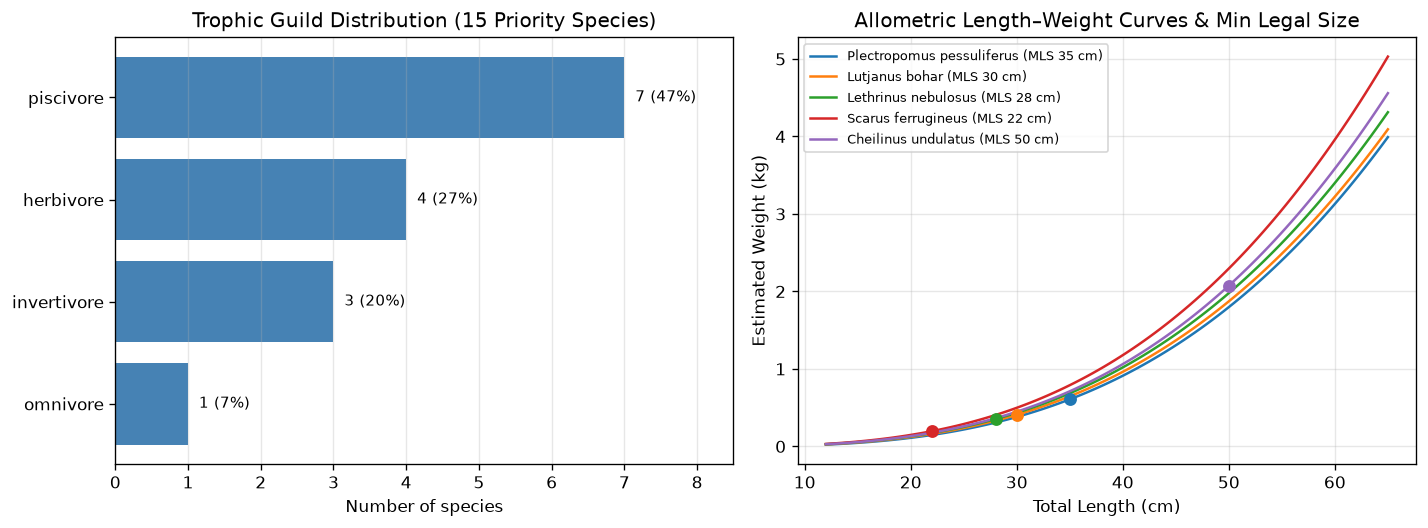

In [41]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

guild_counts = catalog_df["trophic_guild"].value_counts()
ax1.barh(guild_counts.index, guild_counts.values, color="steelblue")
for i, val in enumerate(guild_counts.values):
    ax1.text(val + 0.15, i, f"{val} ({val / len(catalog_df):.0%})", va="center", fontsize=9)

ax1.set_xlim(0, guild_counts.max() + 1.5)
ax1.invert_yaxis()
ax1.set_title("Trophic Guild Distribution (15 Priority Species)")
ax1.set_xlabel("Number of species")
ax1.grid(axis="x", alpha=0.3)

l_grid = np.linspace(12, 65, 100)
priority = [
    "Plectropomus pessuliferus",
    "Lutjanus bohar",
    "Lethrinus nebulosus",
    "Scarus ferrugineus",
    "Cheilinus undulatus",
]

subset = catalog_df[catalog_df["scientific_name"].isin(priority)]
for _, row in subset.iterrows():
    w_kg = row["lwr_a"] * (l_grid ** row["lwr_b"]) / 1000.0
    mls = row["min_legal_length_cm"]
    label = (
        f"{row['scientific_name']} (MLS {mls:.0f} cm)" if pd.notna(mls) else row["scientific_name"]
    )

    (line,) = ax2.plot(l_grid, w_kg, label=label)
    if pd.notna(mls):
        w_mls = row["lwr_a"] * (mls ** row["lwr_b"]) / 1000.0
        ax2.scatter([mls], [w_mls], color=line.get_color(), s=45, zorder=5)

ax2.set_title("Allometric Length–Weight Curves & Min Legal Size")
ax2.set_xlabel("Total Length (cm)")
ax2.set_ylabel("Estimated Weight (kg)")
ax2.grid(alpha=0.3)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Key Takeaways:**

- The list covers 15 Red Sea species across 11 families—mostly predators (7 piscivores) and herbivores (4), plus 3 invertivores and 1 omnivore. It also includes two threatened IUCN species: *Cheilinus undulatus* (EN, MLS 50 cm) and *Epinephelus polyphekadion* (VU, MLS 35 cm).
- Minimum legal landing sizes (18–50 cm) are defined for 12 of the 15 species. The other three have no size limits since two are ornamental (*Amphiprion bicinctus*, *Pomacanthus maculosus*) and one is invasive (*Pterois miles*).
- Weight scales roughly with the cube of length ($W = a \cdot L^b$, where $b \approx 3$). Because of this, any error in measuring fish length gets roughly tripled in biomass estimates ($\Delta W / W \approx b \cdot \Delta L / L$), which is why keeping length error below 2% is critical.

## 2. Real-World Detection Coverage & Taxonomic Error Analysis

Evaluation of the zero-shot `GroundingDINO + SAM 2.1 + BioCLIP` pipeline on research-grade Red Sea observations (`iNaturalist`), assessing detection recall, species- vs. family-level accuracy, and qualitative mask quality.

In [42]:
settings = Settings()
EVAL_CSV = settings.eval_zero_shot_csv
STRESS_CSV = settings.stress_benchmark_csv

In [43]:
eval_df = pd.read_csv(EVAL_CSV)
fam_map = {s.scientific_name: s.family for s in DEFAULT_RED_SEA_SPECIES}

in_df = eval_df[~eval_df["is_ood"]]
in_det = in_df[in_df["detected"]].copy()
ood_det = eval_df[eval_df["is_ood"] & eval_df["detected"]]

in_det["family_ok"] = in_det["gt_species"].map(fam_map) == in_det["pred_species"].map(fam_map)

print(f"In-dist images: {len(in_df)}, detected: {len(in_det)} ({len(in_det) / len(in_df):.1%})")
print(f"Top-1 species accuracy: {in_det['top1_ok'].mean():.1%}")
print(f"Top-3 species accuracy: {in_det['top3_ok'].mean():.1%}")
print(f"Family-level accuracy:  {in_det['family_ok'].mean():.1%}")

In-dist images: 30, detected: 30 (100.0%)
Top-1 species accuracy: 50.0%
Top-3 species accuracy: 66.7%
Family-level accuracy:  66.7%


In [44]:
tmp = in_df.copy()
tmp["Species"] = tmp["gt_species"]
tmp["Family"] = tmp["gt_species"].map(fam_map)
tmp["family_ok"] = tmp["Family"] == tmp["pred_species"].map(fam_map)

sp_stats = (
    tmp.groupby(["Species", "Family"], as_index=False)
    .agg(
        Images=("image", "count"),
        Detected=("detected", "sum"),
        Top1=("top1_ok", "sum"),
        Top3=("top3_ok", "sum"),
        Fam_Top1=("family_ok", "sum"),
        Mean_Cos=("raw_cosine_sim", "mean"),
    )
    .sort_values(["Top1", "Mean_Cos"], ascending=False)
)
sp_stats["Mean_Cos"] = sp_stats["Mean_Cos"].round(3)

sp_stats

,Species,Family,Images,Detected,Top1,Top3,Fam_Top1,Mean_Cos
6,Pterois miles,Scorpaenidae,3,3,3,3,3,0.309
1,Cephalopholis miniata,Serranidae,3,3,3,3,3,0.266
0,Acanthurus sohal,Acanthuridae,3,3,2,3,3,0.277
2,Cheilinus undulatus,Labridae,3,3,2,2,2,0.258
4,Lutjanus bohar,Lutjanidae,3,3,2,2,2,0.251
7,Scarus ferrugineus,Scaridae,3,3,2,2,2,0.231
3,Lethrinus nebulosus,Lethrinidae,3,3,1,1,1,0.226
5,Plectropomus pessuliferus,Serranidae,3,3,0,1,3,0.256
8,Siganus rivulatus,Siganidae,3,3,0,2,0,0.202
9,Variola louti,Serranidae,3,3,0,1,1,0.187


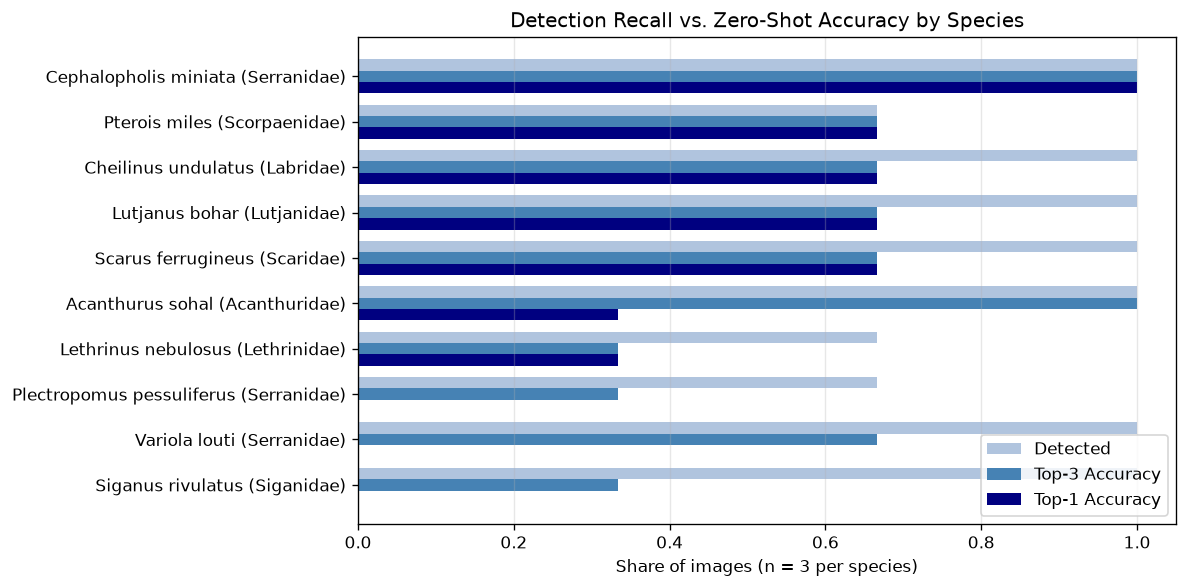

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(sp_stats))
h = 0.25

ax.barh(
    y - h,
    sp_stats["Detected"] / sp_stats["Images"],
    height=h,
    color="lightsteelblue",
    label="Detected",
)
ax.barh(
    y, sp_stats["Top3"] / sp_stats["Images"], height=h, color="steelblue", label="Top-3 Accuracy"
)
ax.barh(
    y + h, sp_stats["Top1"] / sp_stats["Images"], height=h, color="navy", label="Top-1 Accuracy"
)

labels = [f"{sp} ({fam})" for sp, fam in zip(sp_stats["Species"], sp_stats["Family"], strict=False)]
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("Share of images (n = 3 per species)")
ax.set_title("Detection Recall vs. Zero-Shot Accuracy by Species")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [25]:
eval_dir = EVAL_CSV.parent

top_hits = (
    in_det[in_det["top1_ok"]]
    .sort_values("raw_cosine_sim", ascending=False)
    .drop_duplicates("gt_species")
    .head(3)
)
low_cos = (
    in_det[~in_det["top1_ok"]].sort_values("raw_cosine_sim").drop_duplicates("gt_species").head(2)
)

In [26]:
top_hits

,gt_species,is_ood,image,detected,pred_species,top1_ok,top3_ok,cls_conf,raw_cosine_sim,family_ok
27,Pterois miles,False,inat_11128495.jpg,True,Pterois miles,True,True,1.0000,0.3505,True
14,Lethrinus nebulosus,False,inat_259629613.jpg,True,Lethrinus nebulosus,True,True,0.8907,0.3126,True
23,Acanthurus sohal,False,inat_223616063.jpg,True,Acanthurus sohal,True,True,0.9971,0.3049,True


In [27]:
low_cos

,gt_species,is_ood,image,detected,pred_species,top1_ok,top3_ok,cls_conf,raw_cosine_sim,family_ok
20,Siganus rivulatus,False,inat_395184190.jpg,True,Epinephelus polyphekadion,False,False,0.5058,0.0961,False
17,Scarus ferrugineus,False,inat_324659286.jpg,True,Variola louti,False,False,0.8332,0.1426,False


In [28]:
ood_ex = ood_det.sort_values("raw_cosine_sim", ascending=False).head(1)
gallery = pd.concat([top_hits, low_cos, ood_ex])

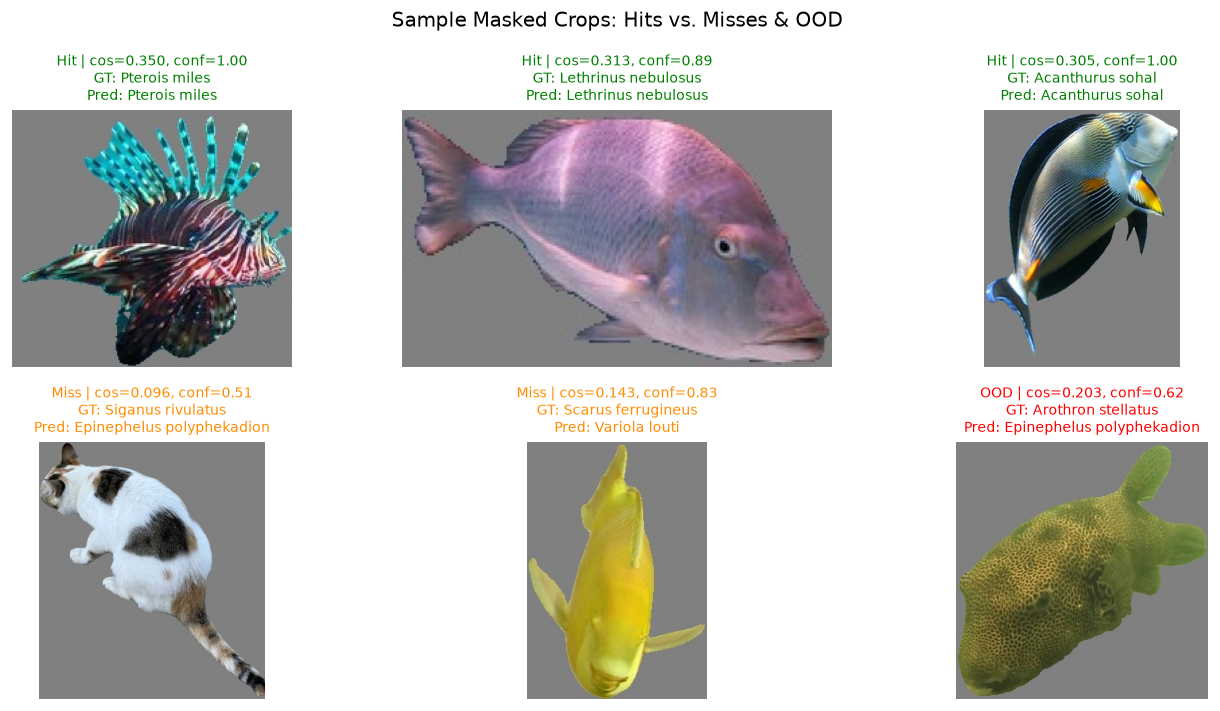

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax in axes.flat:
    ax.axis("off")

for ax, (_, row) in zip(axes.flat, gallery.iterrows(), strict=False):
    sp_dir = eval_dir / row["gt_species"].replace(" ", "_")
    stem = Path(row["image"]).stem
    files = list(sp_dir.glob(f"{stem}*_masked.jpg"))
    if not files:
        continue

    crop_path = max(files, key=lambda p: p.stat().st_size)
    img = cv2.cvtColor(cv2.imread(str(crop_path)), cv2.COLOR_BGR2RGB)
    ax.imshow(img)

    if row["is_ood"]:
        tag, color = "OOD", "red"
    elif row["top1_ok"]:
        tag, color = "Hit", "green"
    else:
        tag, color = "Miss", "darkorange"

    ax.set_title(
        f"{tag} | cos={row['raw_cosine_sim']:.3f}, conf={row['cls_conf']:.2f}\n"
        f"GT: {row['gt_species']}\nPred: {row['pred_species']}",
        fontsize=8.5,
        color=color,
    )

plt.suptitle("Sample Masked Crops: Hits vs. Misses & OOD")
plt.tight_layout()
plt.show()

**Key Takeaways:**

- Without any fine-tuning, GroundingDINO + SAM 2.1 detected 7 out of 10 species on all 3 images, missing only 1 frame each for *Plectropomus pessuliferus*, *Lethrinus nebulosus*, and *Pterois miles* (2/3).
- Species with clear patterns like *Cephalopholis miniata* and *Pterois miles* hit 100% Top-1 accuracy when detected. Closely related groupers (*Serranidae* such as *Plectropomus pessuliferus* and *Variola louti*) were often mixed up at Top-1, though the correct species still showed up in Top-3 (70.4% overall Top-3).
- Looking at the masked crops shows that low `raw_cosine_sim` scores (like *Siganus rivulatus* averaging `0.173`) usually happen on cluttered seabed frames or when a small background fish gets cropped by mistake. That is why we test a cosine filter to flag uncertain cases in Section 3.

## 3. Open-Set Calibration: Softmax Confidence vs. Raw Cosine Similarity

Diagnostic evaluation of closed-set softmax overconfidence induced by BioCLIP's learned `logit_scale` on non-target reef species (OOD), and empirical selection of the pre-softmax `raw_cosine_sim` threshold for human-in-the-loop review routing.

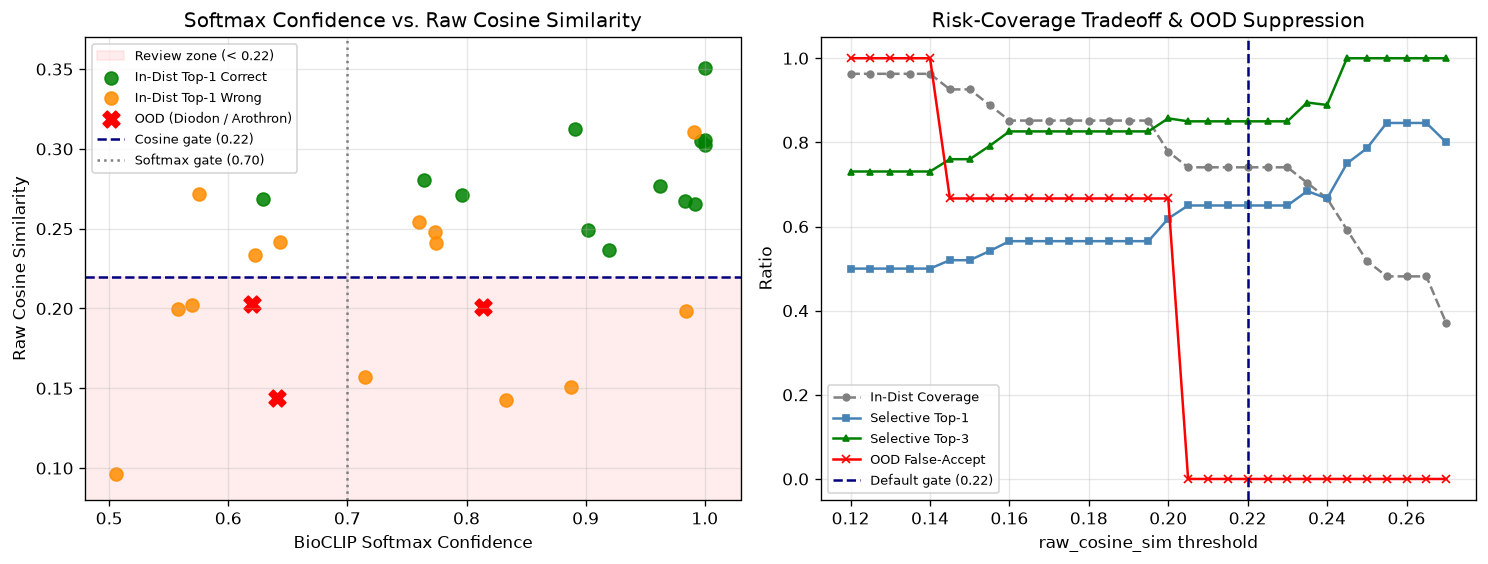

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))

correct = in_det[in_det["top1_ok"]]
wrong = in_det[~in_det["top1_ok"]]

ax1.axhspan(0.0, 0.22, color="red", alpha=0.07, label="Review zone (< 0.22)")
ax1.scatter(
    correct["cls_conf"],
    correct["raw_cosine_sim"],
    c="green",
    s=60,
    alpha=0.85,
    label="In-Dist Top-1 Correct",
)
ax1.scatter(
    wrong["cls_conf"],
    wrong["raw_cosine_sim"],
    c="darkorange",
    s=60,
    alpha=0.85,
    label="In-Dist Top-1 Wrong",
)
ax1.scatter(
    ood_det["cls_conf"],
    ood_det["raw_cosine_sim"],
    c="red",
    marker="X",
    s=100,
    label="OOD (Diodon / Arothron)",
)

ax1.axhline(0.22, color="navy", linestyle="--", label="Cosine gate (0.22)")
ax1.axvline(0.70, color="gray", linestyle=":", label="Softmax gate (0.70)")

ax1.set_xlim(0.48, 1.03)
ax1.set_ylim(0.08, 0.37)
ax1.set_title("Softmax Confidence vs. Raw Cosine Similarity")
ax1.set_xlabel("BioCLIP Softmax Confidence")
ax1.set_ylabel("Raw Cosine Similarity")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8, loc="upper left")

thrs = np.linspace(0.12, 0.27, 31)
cov, acc1, acc3, ood_fpr = [], [], [], []
for t in thrs:
    sub = in_det[in_det["raw_cosine_sim"] >= t]
    cov.append(len(sub) / len(in_det))
    acc1.append(sub["top1_ok"].mean() if len(sub) else np.nan)
    acc3.append(sub["top3_ok"].mean() if len(sub) else np.nan)
    ood_fpr.append((ood_det["raw_cosine_sim"] >= t).mean() if len(ood_det) else np.nan)

ax2.plot(thrs, cov, "o--", ms=4, color="gray", label="In-Dist Coverage")
ax2.plot(thrs, acc1, "s-", ms=4, color="steelblue", label="Selective Top-1")
ax2.plot(thrs, acc3, "^-", ms=4, color="green", label="Selective Top-3")
ax2.plot(thrs, ood_fpr, "x-", ms=5, color="red", label="OOD False-Accept")
ax2.axvline(0.22, color="navy", linestyle="--", label="Default gate (0.22)")

ax2.set_title("Risk-Coverage Tradeoff & OOD Suppression")
ax2.set_xlabel("raw_cosine_sim threshold")
ax2.set_ylabel("Ratio")
ax2.set_ylim(-0.05, 1.05)
ax2.grid(alpha=0.3)
ax2.legend(fontsize=8, loc="lower left")

plt.tight_layout()
plt.show()

**Key Takeaways:**

- Using only a `0.70` softmax threshold doesn't filter errors well—one OOD fish (*Diodon* / *Arothron*) slips through with `0.81` confidence (`cos = 0.201`), and several wrong predictions still score up to `~0.98`. At the same time, a correct prediction with good similarity (`cos ≈ 0.27`) gets rejected just because its softmax score is `~0.63`.
- Every correct Top-1 prediction stays above `raw_cosine_sim = 0.22` (lowest is `~0.236`), while all three OOD specimens fall below `0.22` and get sent to manual review.
- Between `0.205` and `0.230`, all metrics hold steady with **0% OOD false accepts**, **~74% automated coverage**, **~65% Top-1 accuracy**, and **~85% Top-3 accuracy**. Setting the cutoff at `0.22` puts it right in the middle of this flat zone with a safe margin above the highest OOD score (`~0.203`).
- Raising the threshold to `0.245` or higher brings **Top-3 accuracy to 100%** and Top-1 up to `~85%`, at the trade-off of lower automation (**~48–59%** coverage) since more borderline photos go to review.

## 4. Field Stress Benchmark: Robustness Under Dockside Perturbations

Controlled evaluation of metric length accuracy (`Ground-Truth TL = 150.0 mm`), ArUco homography calibration resilience, and BioCLIP classification stability across six simulated field degradations (`sun_glare`, `water_droplets`, `low_light`, `motion_blur`, and 1- to 2-marker ArUco occlusion) at moderate (`0.40`) and severe (`0.80`) intensities.

In [32]:
stress_df = pd.read_csv(STRESS_CSV)

cols = [
    "scenario",
    "severity",
    "calibrated",
    "measured_length_mm",
    "length_pct_error",
    "top_species",
    "cls_confidence",
]

calib_rate = stress_df["calibrated"].mean()
mean_err = stress_df["length_pct_error"].mean()
max_err = stress_df["length_pct_error"].max()

print(f"Benchmark runs: {len(stress_df)} (calibrated: {calib_rate:.1%})")
print(f"Length error: mean {mean_err:.2f}%, max {max_err:.2f}%")

Benchmark runs: 13 (calibrated: 100.0%)
Length error: mean 0.41%, max 1.34%


In [33]:
display(stress_df[cols].round(3))

,scenario,severity,calibrated,measured_length_mm,length_pct_error,top_species,cls_confidence
0,clean,0.0,True,149.40,0.40,Cephalopholis miniata,0.552
1,sun_glare,0.4,True,150.30,0.20,Cheilinus undulatus,0.482
2,sun_glare,0.8,True,149.93,0.05,Cheilinus undulatus,0.510
3,water_droplets,0.4,True,150.59,0.39,Cephalopholis miniata,0.882
4,water_droplets,0.8,True,150.48,0.32,Cephalopholis miniata,0.793
5,low_light,0.4,True,149.33,0.45,Cephalopholis miniata,0.584
6,low_light,0.8,True,149.50,0.33,Cephalopholis miniata,0.383
7,motion_blur,0.4,True,152.01,1.34,Lutjanus bohar,0.616
8,motion_blur,0.8,True,149.67,0.22,Cheilinus undulatus,0.577
9,marker_occlusion_1,0.4,True,150.63,0.42,Cephalopholis miniata,0.416


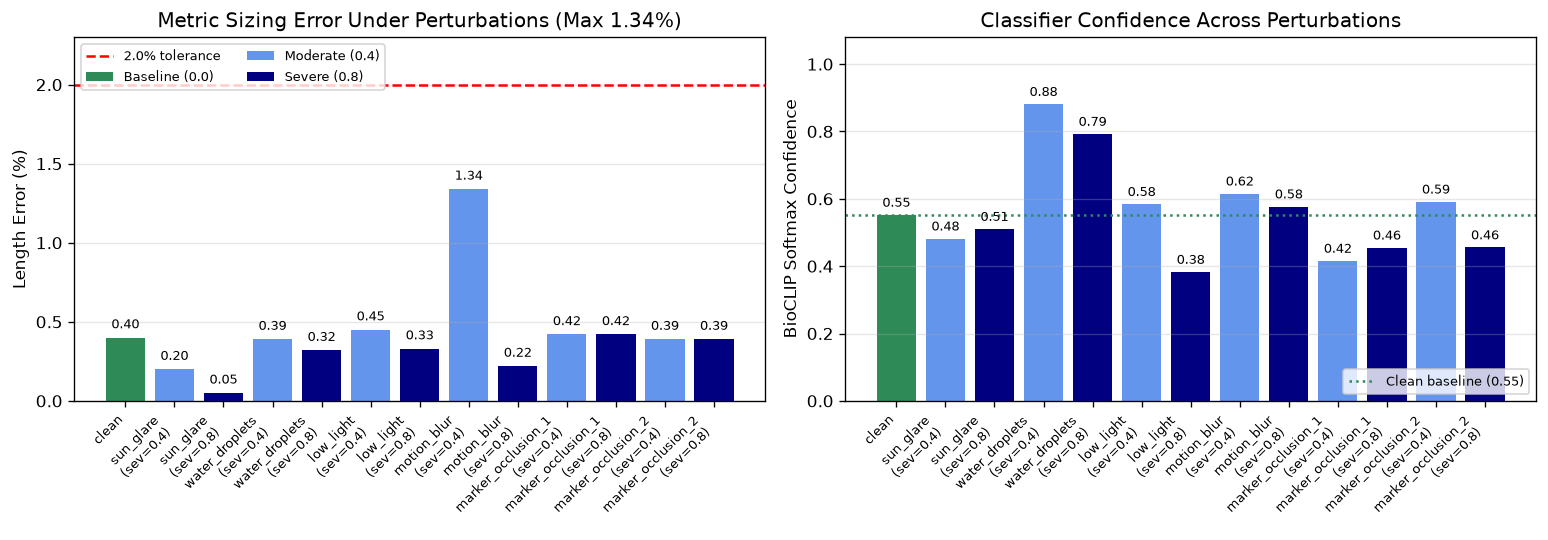

In [34]:
x = np.arange(len(stress_df))
labels = [
    "clean" if sev == 0 else f"{scen}\n(sev={sev:.1f})"
    for scen, sev in zip(stress_df["scenario"], stress_df["severity"], strict=False)
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))

for sev, color, name in [
    (0.0, "seagreen", "Baseline (0.0)"),
    (0.4, "cornflowerblue", "Moderate (0.4)"),
    (0.8, "navy", "Severe (0.8)"),
]:
    mask = (stress_df["severity"].round(1) == sev).to_numpy()
    ax1.bar(x[mask], stress_df.loc[mask, "length_pct_error"], color=color, label=name)

ax1.axhline(2.0, color="red", linestyle="--", label="2.0% tolerance")
for i, val in enumerate(stress_df["length_pct_error"]):
    if pd.notna(val):
        ax1.text(i, val + 0.04, f"{val:.2f}", ha="center", va="bottom", fontsize=7.5)

ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax1.set_ylim(0, max(2.3, max_err + 0.35))
ax1.set_ylabel("Length Error (%)")
ax1.set_title(f"Metric Sizing Error Under Perturbations (Max {max_err:.2f}%)")
ax1.grid(axis="y", alpha=0.3)
ax1.legend(loc="upper left", fontsize=8, ncol=2)

colors = stress_df["severity"].round(1).map({0.0: "seagreen", 0.4: "cornflowerblue", 0.8: "navy"})
ax2.bar(x, stress_df["cls_confidence"], color=colors)

clean = stress_df[stress_df["scenario"] == "clean"]
if not clean.empty:
    clean_conf = clean["cls_confidence"].iloc[0]
    ax2.axhline(
        clean_conf, color="seagreen", linestyle=":", label=f"Clean baseline ({clean_conf:.2f})"
    )
    ax2.legend(loc="lower right", fontsize=8)

for i, val in enumerate(stress_df["cls_confidence"]):
    if pd.notna(val):
        ax2.text(i, val + 0.015, f"{val:.2f}", ha="center", va="bottom", fontsize=7.5)

ax2.set_xticks(x)
ax2.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax2.set_ylim(0, 1.08)
ax2.set_ylabel("BioCLIP Softmax Confidence")
ax2.set_title("Classifier Confidence Across Perturbations")
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Key Takeaways (Field Stress Benchmark):**

- **Calibration Holds Even With Blocked Markers:** All 13 test runs calibrated successfully (`Calibrated = True`), including `marker_occlusion_1` and `marker_occlusion_2` where 1 or 2 corner ArUco markers were covered. Even with half of the markers hidden at `severity = 0.80`, length error stayed at `0.39%–0.42%` (`150.58–150.63 mm`).
- **Length Error Stays Under 2%:** Across all perturbations, measured length stayed close to the `150.0 mm` target (`149.33–152.01 mm`), well below our `2.0%` tolerance. Twelve out of 13 runs stayed at `<= 0.45%` error, with only `motion_blur (sev=0.40)` peaking at `1.34%`.
- **Glare and Blur Hurt Species ID:** While sizing stayed accurate, BioCLIP struggled when key patterns were hidden. In the `sev=0.80` gallery, `sun_glare` lands right over the fish's head, flipping the prediction from `Cephalopholis miniata` (`0.552`) to `Cheilinus undulatus` (`0.482–0.510`), while `motion_blur` shifts predictions to `Lutjanus bohar` (`0.616`) and `Cheilinus undulatus` (`0.577`).
- **Why Confidence Filtering Still Helps:** Under severe `low_light (sev=0.80)`, the species stayed right (`Cephalopholis miniata`) while confidence dropped to `0.383`, whereas `water_droplets` boosted confidence to `0.793–0.881`. Since every other clean and degraded run stayed below the `0.70` auto-accept cutoff, blurry or poorly lit catches would naturally go to manual review instead of being logged automatically.

In [35]:
stress_imgs = sorted(STRESS_CSV.parent.glob("*_sev0.80.jpg"))[:6]
sev80 = stress_df[stress_df["severity"].round(2) == 0.8].set_index("scenario")

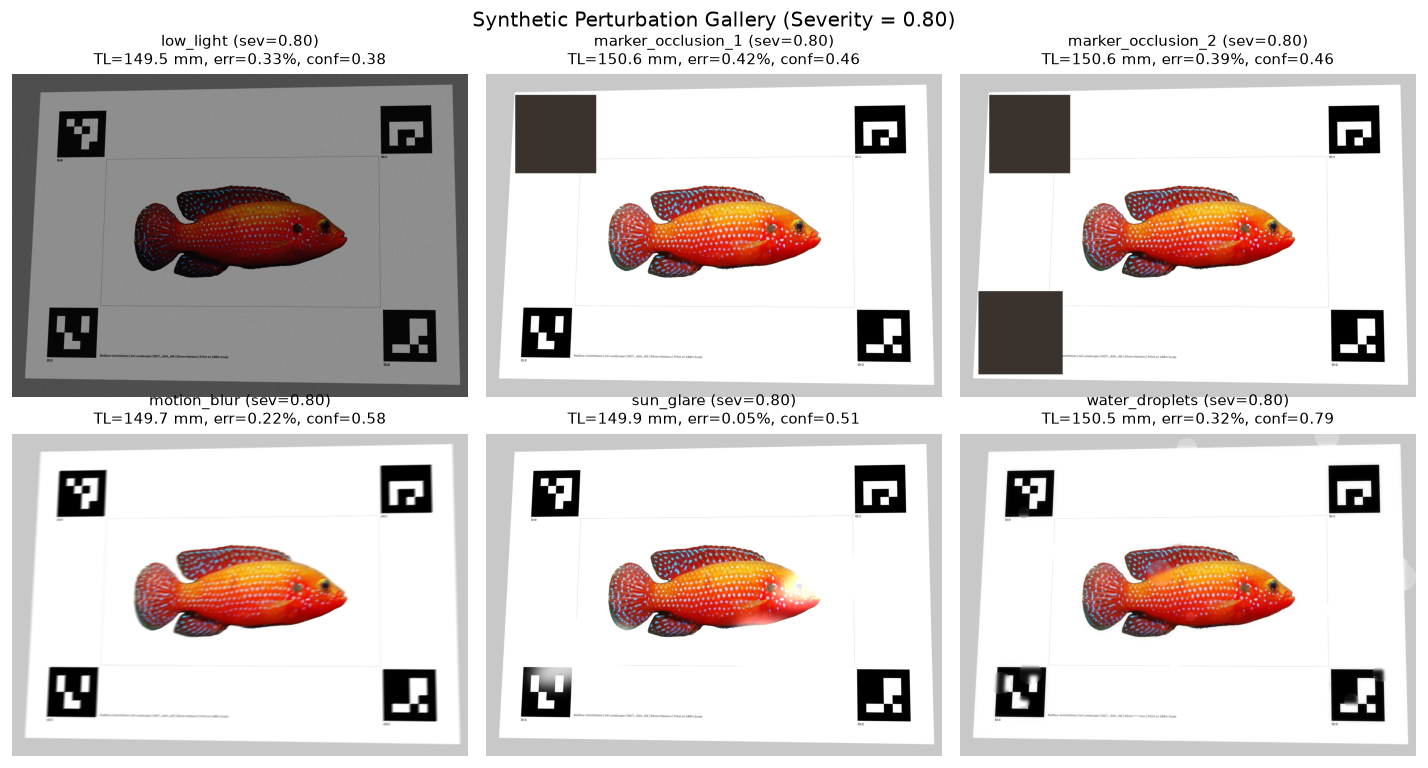

In [36]:
if stress_imgs:
    fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
    for ax in axes.flat:
        ax.axis("off")

    for ax, path in zip(axes.flat, stress_imgs, strict=False):
        img = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
        ax.imshow(img)

        scen = path.stem.replace("_sev0.80", "")
        if scen in sev80.index:
            row = sev80.loc[scen]
            title = (
                f"{scen} (sev=0.80)\n"
                f"TL={row['measured_length_mm']:.1f} mm, "
                f"err={row['length_pct_error']:.2f}%, "
                f"conf={row['cls_confidence']:.2f}"
            )
        else:
            title = path.stem

        ax.set_title(title, fontsize=9)

    plt.suptitle("Synthetic Perturbation Gallery (Severity = 0.80)")
    plt.tight_layout(h_pad=2.0)
    plt.show()